Mounted at /content/drive
Device: cuda
GPU: Tesla T4

================ 1. Exploratory Data Analysis (EDA) ================
Total dataset size: 27000 images
Number of classes: 10

--- Class Distribution ---
 - AnnualCrop               : 3000 images
 - Forest                   : 3000 images
 - HerbaceousVegetation     : 3000 images
 - Highway                  : 2500 images
 - Industrial               : 2500 images
 - Pasture                  : 2000 images
 - PermanentCrop            : 2500 images
 - Residential              : 3000 images
 - River                    : 2500 images
 - SeaLake                  : 3000 images


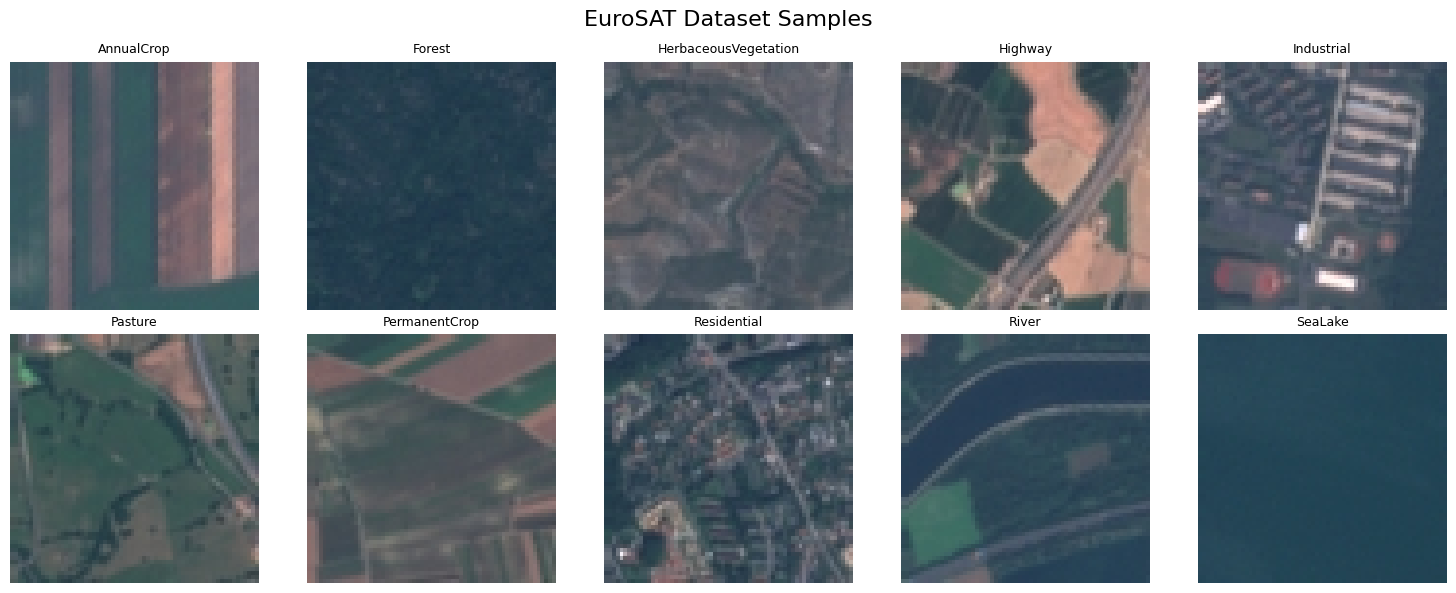


================ 2. Dataset Splits ================
Train samples      : 18900 (70.0%)
Validation samples : 4050 (15.0%)
Test samples       : 4050 (15.0%)


model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/timm/layers/interpolate.py:47: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at /pytorch/aten/src/ATen/native/BucketizationUtils.h:32.)
  idx_right = torch.bucketize(x, p)
/usr/local/lib/python3.13/dist-packages/timm/layers/interpolate.py:65: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  numerator += self.values[as_s] * \
/tmp/ipykernel_50302/789024249.py:169


================ 3. Training Swin Transformer Model ================

--- Epoch 1/15 ---


Train batches:   0%|          | 0/591 [00:00<?, ?it/s]/tmp/ipykernel_50302/789024249.py:181: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


... (12 outputs left out)

 Train Loss: 0.0047 | Acc: 99.84%
 Val   Loss: 0.0649 | Acc: 98.49%

--- Epoch 14/15 ---


 Train Loss: 0.0034 | Acc: 99.89%
 Val   Loss: 0.0684 | Acc: 98.42%

--- Epoch 15/15 ---


 Train Loss: 0.0032 | Acc: 99.90%
 Val   Loss: 0.0618 | Acc: 98.72%

================ 4. Final Evaluation on TEST Set ================



---------------- Swin TEST Results ----------------
Test Loss          : 0.0682
Test Accuracy      : 98.27%
Precision (Macro)  : 0.9823
Recall (Macro)     : 0.9822
F1-Score (Macro)   : 0.9822
Precision (Weighted): 0.9827
Recall (Weighted)  : 0.9827
F1-Score (Weighted): 0.9827
ROC-AUC (OVR)      : 0.9997
---------------------------------------------------
Saved confusion matrix to: /content/drive/MyDrive/V/eurosat_swin_test_confusion_matrix.png

Swin Execution Completed Successfully! Test Acc: 98.27%


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import itertools

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import transforms, datasets

from sklearn.metrics import (
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score
)


!pip install -q timm
import timm

# -------------------- USER CONFIG --------------------
DATA_ROOT = "/content/drive/MyDrive/EuroSAT_RGB"

SAVE_DIR = "/content/drive/MyDrive/V"
os.makedirs(SAVE_DIR, exist_ok=True)

BATCH_SIZE = 32
IMAGE_SIZE = 64           
NUM_EPOCHS = 15
LR = 1e-4
WEIGHT_DECAY = 1e-3
NUM_WORKERS = 2
SAVE_PATH = os.path.join(SAVE_DIR, "best_eurosat_swin.pth")
CONF_MATRIX_PATH = os.path.join(SAVE_DIR, "eurosat_swin_test_confusion_matrix.png")
USE_PRETRAINED = True
USE_AMP = True
SEED = 42
# -----------------------------------------------------

# Reproducibility
random.seed(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

torch.backends.cudnn.benchmark = True

# ---------------- Transforms ----------------
train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# ---------------- Dataset & EDA ----------------
full_dataset = datasets.ImageFolder(root=DATA_ROOT)
class_names = full_dataset.classes
num_classes = len(class_names)

print("\n================ 1. Exploratory Data Analysis (EDA) ================")
print(f"Total dataset size: {len(full_dataset)} images")
print(f"Number of classes: {num_classes}")

print("\n--- Class Distribution ---")
for cls in class_names:
    cls_path = os.path.join(DATA_ROOT, cls)
    if os.path.exists(cls_path):
        count = len([f for f in os.listdir(cls_path) if os.path.isfile(os.path.join(cls_path, f))])
        print(f" - {cls:<25}: {count} images")

# Sample Visualization
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('EuroSAT Dataset Samples', fontsize=16)
for i, cls in enumerate(class_names):
    cls_path = os.path.join(DATA_ROOT, cls)
    img_name = [f for f in os.listdir(cls_path) if os.path.isfile(os.path.join(cls_path, f))][0]
    img = plt.imread(os.path.join(cls_path, img_name))
    ax = axes[i // 5, i % 5]
    ax.imshow(img)
    ax.set_title(cls, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

# ---------------- Train / Val / Test Splits (70% / 15% / 15%) ----------------
total_len = len(full_dataset)
train_size = int(0.70 * total_len)
val_size   = int(0.15 * total_len)
test_size  = total_len - train_size - val_size

train_subset, val_subset, test_subset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(SEED)
)

class DatasetWrapper(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

train_dataset = DatasetWrapper(train_subset, transform=train_transforms)
val_dataset   = DatasetWrapper(val_subset, transform=eval_transforms)
test_dataset  = DatasetWrapper(test_subset, transform=eval_transforms)

pin_memory_flag = True if torch.cuda.is_available() else False

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=pin_memory_flag
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory_flag
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory_flag
)

print("\n================ 2. Dataset Splits ================")
print(f"Train samples      : {len(train_dataset)} ({len(train_dataset)/total_len*100:.1f}%)")
print(f"Validation samples : {len(val_dataset)} ({len(val_dataset)/total_len*100:.1f}%)")
print(f"Test samples       : {len(test_dataset)} ({len(test_dataset)/total_len*100:.1f}%)")

# -------- Model: Swin Transformer --------
model = timm.create_model(
    'swin_base_patch4_window7_224',
    pretrained=USE_PRETRAINED,
    num_classes=num_classes,
    img_size=IMAGE_SIZE
)
model = model.to(DEVICE)

# Loss, Optimizer, Scheduler, Scaler
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
scaler    = torch.cuda.amp.GradScaler(enabled=USE_AMP and torch.cuda.is_available())

# -------- Training / Evaluation Functions --------
def train_one_epoch(model, loader, criterion, optimizer, device, scaler=None):
    model.train()
    running_loss, running_corrects, n = 0.0, 0, 0
    pbar = tqdm(loader, desc="Train batches", leave=False)
    for inputs, labels in pbar:
        inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        preds = outputs.argmax(dim=1)
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels).item()
        n += inputs.size(0)
        pbar.set_postfix(loss=running_loss / n, acc=100.0 * running_corrects / n)
    return running_loss / n, running_corrects / n

def eval_one_epoch(model, loader, criterion, device, return_full_metrics=False):
    model.eval()
    running_loss, running_corrects, n = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        pbar = tqdm(loader, desc="Evaluating", leave=False)
        for inputs, labels in pbar:
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            probs = F.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels).item()
            n += inputs.size(0)

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())
            all_probs.append(probs.cpu().numpy())
            pbar.set_postfix(eval_loss=running_loss / n, eval_acc=100.0 * running_corrects / n)

    eval_loss = running_loss / n
    eval_acc  = running_corrects / n

    if return_full_metrics:
        preds_arr  = np.concatenate(all_preds)
        labels_arr = np.concatenate(all_labels)
        probs_arr  = np.concatenate(all_probs)

        prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(labels_arr, preds_arr, average='macro')
        prec_w, rec_w, f1_w, _            = precision_recall_fscore_support(labels_arr, preds_arr, average='weighted')

        try:
            auc_ovr = roc_auc_score(labels_arr, probs_arr, multi_class='ovr', average='macro')
        except Exception:
            auc_ovr = 0.0

        metrics = {
            'accuracy': eval_acc,
            'precision_macro': prec_macro,
            'recall_macro': rec_macro,
            'f1_macro': f1_macro,
            'precision_weighted': prec_w,
            'recall_weighted': rec_w,
            'f1_weighted': f1_w,
            'roc_auc_ovr': auc_ovr,
            'preds': preds_arr,
            'labels': labels_arr,
            'probs': probs_arr
        }
        return eval_loss, eval_acc, metrics

    return eval_loss, eval_acc

# -------- Confusion Matrix Helper --------
def plot_confusion_matrix(cm, class_names, normalize=True, cmap=plt.cm.Blues, out_path=None):
    if normalize:
        cm_sum = cm.sum(axis=1)[:, np.newaxis]
        cm = np.divide(cm, cm_sum, where=cm_sum != 0)
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title("Swin Transformer Test Confusion Matrix" + (" (normalized)" if normalize else ""))
    plt.colorbar(fraction=0.046, pad=0.04)
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45, ha="right", fontsize=9)
    plt.yticks(tick_marks, class_names, fontsize=9)

    thresh = cm.max() / 2.0 if cm.max() != 0 else 0.5
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        val = cm[i, j]
        display = format(val, '.2f') if normalize else format(int(val), 'd')
        plt.text(j, i, display, horizontalalignment="center",
                 color="white" if val > thresh else "black", fontsize=8)

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    if out_path:
        plt.savefig(out_path, bbox_inches='tight', dpi=200)
        print("Saved confusion matrix to:", out_path)
    plt.close()

# -------- Training Loop --------
print("\n================ 3. Training Swin Transformer Model ================")
best_val_acc = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

for epoch in range(1, NUM_EPOCHS + 1):
    print(f"\n--- Epoch {epoch}/{NUM_EPOCHS} ---")
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE, scaler=scaler if USE_AMP else None)
    val_loss, val_acc     = eval_one_epoch(model, val_loader, criterion, DEVICE)

    print(f" Train Loss: {train_loss:.4f} | Acc: {100.0 * train_acc:.2f}%")
    print(f" Val   Loss: {val_loss:.4f} | Acc: {100.0 * val_acc:.2f}%")

    scheduler.step(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save({
            'model_state_dict': best_model_wts,
            'best_val_acc': best_val_acc,
            'classes': class_names
        }, SAVE_PATH)
        print(f" Saved best Swin model -> {SAVE_PATH}")

# ------ Final Evaluation on TEST Dataset ------
print("\n================ 4. Final Evaluation on TEST Set ================")
checkpoint = torch.load(SAVE_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])

test_loss, test_acc, test_metrics = eval_one_epoch(model, test_loader, criterion, DEVICE, return_full_metrics=True)

print("\n---------------- Swin TEST Results ----------------")
print(f"Test Loss          : {test_loss:.4f}")
print(f"Test Accuracy      : {test_metrics['accuracy'] * 100:.2f}%")
print(f"Precision (Macro)  : {test_metrics['precision_macro']:.4f}")
print(f"Recall (Macro)     : {test_metrics['recall_macro']:.4f}")
print(f"F1-Score (Macro)   : {test_metrics['f1_macro']:.4f}")
print(f"Precision (Weighted): {test_metrics['precision_weighted']:.4f}")
print(f"Recall (Weighted)  : {test_metrics['recall_weighted']:.4f}")
print(f"F1-Score (Weighted): {test_metrics['f1_weighted']:.4f}")
print(f"ROC-AUC (OVR)      : {test_metrics['roc_auc_ovr']:.4f}")
print("---------------------------------------------------")

cm = confusion_matrix(test_metrics['labels'], test_metrics['preds'])
plot_confusion_matrix(cm, class_names, normalize=True, out_path=CONF_MATRIX_PATH)

print(f"\nSwin Execution Completed Successfully! Test Acc: {100.0 * test_acc:.2f}%")